# Keyword Spotting — Extraction MFCC + Entrainement MLP (v3)

Pipeline complet pour le projet audio Zybo :
1. Detection automatique du dataset Speech Commands ajoute via *Add Input*
2. Extraction des features MFCC **mean + std** (26 valeurs au lieu de 13 — v3)
3. Classe "unknown" equilibree avec tous les mots disponibles **+ segments de bruit de fond** (v3)
4. Entrainement d'un MLP (128/64/32) avec **class_weight**, **ModelCheckpoint** et **EarlyStopping**
5. Evaluation + sauvegarde du modele final et des parametres de normalisation

**Avant de lancer :** ajoute ton dataset via le bouton *Add Input* (cherche "speech commands"),
et verifie qu'il contient bien des dossiers `yes/`, `no/`, etc. avec des fichiers `.wav` dedans,
ainsi qu'un dossier `_background_noise_/`.
Active aussi le GPU si disponible : Settings (icone roue dentee) -> Accelerator -> GPU.

**Changelog v3** (par rapport a v2, qui donnait 70% accuracy / 55% recall sur "unknown") :
- Feature vector etendu de 13 (mean seul) a **26 valeurs (mean + std)** par MFCC : capture la
  variabilite temporelle du mot, pas seulement sa valeur moyenne — utile quand deux classes ont
  un contenu frequentiel moyen proche mais une evolution dans le temps differente.
- Ajout de segments d'1 seconde decoupes dans `_background_noise_/` comme exemples supplementaires
  de la classe "unknown" — dans l'usage reel sur la carte, "unknown" doit aussi couvrir le silence
  et le bruit ambiant, pas seulement d'autres mots.

**Important pour la suite (etape A7 sur l'ARM)** : le calcul cote C devra aussi produire l'ecart-type
en plus de la moyenne sur les blocs de 512 echantillons, pas seulement la moyenne comme prevu avant.


In [5]:

import os, glob
import numpy as np
import librosa
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

# ============================================================
# CONFIGURATION
# ============================================================
TARGET_SR   = 48000     # aligne sur le codec materiel
FRAME_SIZE  = 512       # meme taille que le buffer FPGA
N_MELS      = 26
N_MFCC      = 13
N_FEATURES  = N_MFCC * 2   # mean + std (v3)
WORKING_DIR = "/kaggle/working"
FEATURES_X  = os.path.join(WORKING_DIR, "X_features.npy")
FEATURES_Y  = os.path.join(WORKING_DIR, "y_labels.npy")
BEST_MODEL_PATH  = os.path.join(WORKING_DIR, "best_model.keras")
FINAL_MODEL_PATH = os.path.join(WORKING_DIR, "keyword_spotting_model.keras")

print("TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices('GPU'))


TensorFlow: 2.20.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [6]:

# ============================================================
# SUPPRESSION DU CACHE — force une nouvelle extraction avec les
# features mean+std et les segments de bruit (v3). Necessaire si
# tu as deja des .npy generes par v1/v2 (13 valeurs, pas de bruit).
# ============================================================
for f in [FEATURES_X, FEATURES_Y]:
    if os.path.exists(f):
        os.remove(f)
        print("Supprime :", f)


In [7]:

# ============================================================
# 1. DETECTION AUTOMATIQUE DU DOSSIER DATASET
# ============================================================
def find_dataset_root():
    for root, dirs, files in os.walk("/kaggle/input"):
        if "yes" in dirs and "no" in dirs:
            return root
    raise FileNotFoundError(
        "Impossible de trouver un dossier contenant 'yes' et 'no'. "
        "Verifie que le dataset est bien ajoute (Add Input) et affiche "
        "os.listdir('/kaggle/input') pour inspecter manuellement."
    )

if not (os.path.exists(FEATURES_X) and os.path.exists(FEATURES_Y)):
    DATASET_DIR = find_dataset_root()
    print(f"Dataset trouve dans : {DATASET_DIR}")
else:
    DATASET_DIR = None
    print("Features deja extraites, on saute l'extraction (cache trouve).")


Dataset trouve dans : /kaggle/input/datasets/mok0na/speech-commands-v002/data


In [8]:
# ============================================================
# 2. EXTRACTION DES FEATURES MFCC MEAN+STD (v3) — avec cache
# ============================================================

def extract_mfcc_features(y):
    """Prend un signal deja charge/pad/tronque a TARGET_SR echantillons."""
    
    mfcc = librosa.feature.mfcc(
        y=y,
        sr=TARGET_SR,
        n_mfcc=N_MFCC,
        n_fft=FRAME_SIZE,
        hop_length=FRAME_SIZE,
        n_mels=N_MELS,
        window="hann"
    )
    
    # Moyenne + écart-type pour chaque coefficient MFCC
    return np.concatenate([
        mfcc.mean(axis=1),
        mfcc.std(axis=1)
    ])  # 26 valeurs


def extract_mfcc_from_file(filepath):
    y, _ = librosa.load(filepath, sr=TARGET_SR)

    # Padding si le fichier est plus court que 1 seconde
    if len(y) < TARGET_SR:
        y = np.pad(
            y,
            (0, TARGET_SR - len(y))
        )

    # Tronquage si le fichier est plus long que 1 seconde
    else:
        y = y[:TARGET_SR]

    return extract_mfcc_features(y)


def build_dataset(dataset_dir):

    X, y_labels = [], []

    classes = {
        "yes": 0,
        "no": 1
    }

    counts = {}

    # ========================================================
    # YES / NO
    # ========================================================

    for word, label in classes.items():

        files = glob.glob(
            os.path.join(dataset_dir, word, "*.wav")
        )

        for f in files:
            X.append(extract_mfcc_from_file(f))
            y_labels.append(label)

        counts[word] = len(files)

        print(f"{word}: {len(files)} fichiers traites")

    # ========================================================
    # EQUILIBRAGE YES / NO
    # ========================================================

    target_total = max(
        counts["yes"],
        counts["no"]
    )

    # ========================================================
    # UNKNOWN WORDS
    # ========================================================

    other_words = [
        d for d in os.listdir(dataset_dir)
        if os.path.isdir(os.path.join(dataset_dir, d))
        and d not in classes
        and d != "_background_noise_"
    ]

    n_words = len(other_words)

    # 75 % unknown words
    # 25 % background noise

    words_target = int(target_total * 0.75)
    noise_target = target_total - words_target

    samples_per_word = words_target // n_words + 1

    unknown_files = []

    for w in other_words:

        unknown_files += glob.glob(
            os.path.join(dataset_dir, w, "*.wav")
        )[:samples_per_word]

    for f in unknown_files:

        X.append(
            extract_mfcc_from_file(f)
        )

        y_labels.append(2)

    counts["unknown_words"] = len(unknown_files)

    print(
        f"unknown (mots): {len(unknown_files)} fichiers traites "
        f"({n_words} mots x ~{samples_per_word} fichiers)"
    )

    # ========================================================
    # BACKGROUND NOISE
    # ========================================================

    noise_dir = os.path.join(
        dataset_dir,
        "_background_noise_"
    )

    n_noise_segments = 0

    if os.path.isdir(noise_dir):

        noise_files = glob.glob(
            os.path.join(noise_dir, "*.wav")
        )

        if len(noise_files) > 0:

            segments_per_file = max(
                1,
                noise_target // len(noise_files)
            )

            for f in noise_files:

                y_full, _ = librosa.load(
                    f,
                    sr=TARGET_SR
                )

                n_available = len(y_full) // TARGET_SR

                n_take = min(
                    n_available,
                    segments_per_file
                )

                for i in range(n_take):

                    segment = y_full[
                        i * TARGET_SR:
                        (i + 1) * TARGET_SR
                    ]

                    X.append(
                        extract_mfcc_features(segment)
                    )

                    y_labels.append(2)

                    n_noise_segments += 1

    counts["unknown_noise"] = n_noise_segments

    print(
        f"unknown (bruit de fond) : "
        f"{n_noise_segments} segments traites"
    )

    # ========================================================
    # REPARTITION FINALE
    # ========================================================

    counts["unknown_total"] = (
        counts["unknown_words"]
        + counts["unknown_noise"]
    )

    print("Repartition finale :", counts)

    return (
        np.array(X, dtype=np.float32),
        np.array(y_labels, dtype=np.int32)
    )


# ============================================================
# BUILD / LOAD DATASET
# ============================================================

if DATASET_DIR is not None:

    X, y_labels = build_dataset(DATASET_DIR)

    np.save(FEATURES_X, X)
    np.save(FEATURES_Y, y_labels)

else:

    X = np.load(FEATURES_X)
    y_labels = np.load(FEATURES_Y)


print(
    "Shape features :",
    X.shape,
    "| Shape labels :",
    y_labels.shape
)


# ============================================================
# VERIFICATION
# ============================================================

assert X.shape[1] == N_FEATURES, (
    f"Attendu {N_FEATURES} features, "
    f"obtenu {X.shape[1]} — "
    f"supprime le cache et relance."
)

yes: 4044 fichiers traites
no: 3941 fichiers traites
unknown (mots): 2871 fichiers traites (35 mots x ~87 fichiers)
unknown (bruit de fond) : 398 segments traites
Repartition finale : {'yes': 4044, 'no': 3941, 'unknown_words': 2871, 'unknown_noise': 398, 'unknown_total': 3269}
Shape features : (11254, 26) | Shape labels : (11254,)


In [9]:

# ============================================================
# 3. SPLIT TRAIN / VAL / TEST
# ============================================================
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y_labels, test_size=0.3, stratify=y_labels, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42
)
print(f"Train: {X_train.shape[0]} | Val: {X_val.shape[0]} | Test: {X_test.shape[0]}")

# normalisation (moyenne/ecart-type calcules sur le train uniquement)
mean = X_train.mean(axis=0)
std  = X_train.std(axis=0) + 1e-8
X_train = (X_train - mean) / std
X_val   = (X_val   - mean) / std
X_test  = (X_test  - mean) / std
np.save(os.path.join(WORKING_DIR, "norm_mean.npy"), mean)
np.save(os.path.join(WORKING_DIR, "norm_std.npy"), std)


Train: 7877 | Val: 1688 | Test: 1689


In [10]:

# ============================================================
# POIDS PAR CLASSE — compense le fait que "unknown" reste plus
# difficile a apprendre (plus varie en nature) meme une fois equilibre
# ============================================================
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(enumerate(class_weights))
print("Poids par classe :", class_weight_dict)


Poids par classe : {0: np.float64(0.9274696809136936), 1: np.float64(0.9520183708000967), 2: np.float64(1.1475815850815851)}


In [11]:

# ============================================================
# 4. MODELE MLP (128, 64, 32) — entree elargie a 26 features (v3)
# ============================================================
model = keras.Sequential([
    keras.layers.Input(shape=(N_FEATURES,)),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(3, activation="softmax")   # yes / no / unknown
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()


I0000 00:00:1788142764.917408      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1788142764.920516      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         3,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,891 (54.26 KB)

 Trainable params: 13,891 (54.26 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:

# ============================================================
# 5. CALLBACKS : CHECKPOINT + EARLYSTOPPING
# ============================================================
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=BEST_MODEL_PATH,
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=15,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=7,
        min_lr=1e-6,
        verbose=1
    )
]

# ============================================================
# 6. ENTRAINEMENT
# ============================================================
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=200,                 # EarlyStopping arretera avant si besoin
    batch_size=32,
    callbacks=callbacks,
    class_weight=class_weight_dict,
    verbose=2
)


Epoch 1/200


I0000 00:00:1788142770.740020     153 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.



Epoch 1: val_accuracy improved from None to 0.74408, saving model to /kaggle/working/best_model.keras

Epoch 1: finished saving model to /kaggle/working/best_model.keras
247/247 - 7s - 28ms/step - accuracy: 0.6617 - loss: 0.7292 - val_accuracy: 0.7441 - val_loss: 0.5837 - learning_rate: 0.0010
Epoch 2/200

Epoch 2: val_accuracy improved from 0.74408 to 0.76363, saving model to /kaggle/working/best_model.keras

Epoch 2: finished saving model to /kaggle/working/best_model.keras
247/247 - 1s - 3ms/step - accuracy: 0.7447 - loss: 0.5944 - val_accuracy: 0.7636 - val_loss: 0.5387 - learning_rate: 0.0010
Epoch 3/200

Epoch 3: val_accuracy improved from 0.76363 to 0.77962, saving model to /kaggle/working/best_model.keras

Epoch 3: finished saving model to /kaggle/working/best_model.keras
247/247 - 1s - 3ms/step - accuracy: 0.7643 - loss: 0.5583 - val_accuracy: 0.7796 - val_loss: 0.5217 - learning_rate: 0.0010
Epoch 4/200

Epoch 4: val_accuracy improved from 0.77962 to 0.78021, saving model to

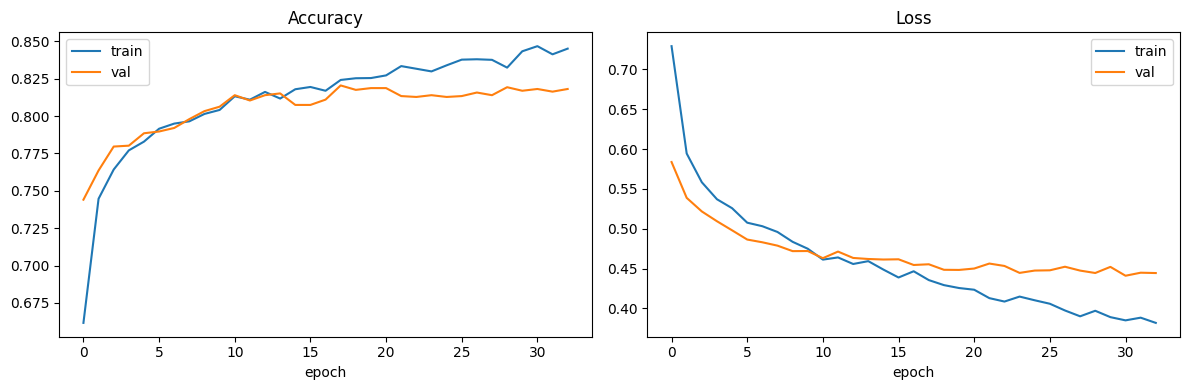

In [13]:

# ============================================================
# (optionnel) COURBES D'ENTRAINEMENT
# ============================================================
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="train")
axes[0].plot(history.history["val_accuracy"], label="val")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("epoch")
axes[0].legend()

axes[1].plot(history.history["loss"], label="train")
axes[1].plot(history.history["val_loss"], label="val")
axes[1].set_title("Loss")
axes[1].set_xlabel("epoch")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(WORKING_DIR, "training_curves.png"), dpi=120)
plt.show()


In [14]:

# ============================================================
# 7. EVALUATION SUR LE TEST SET
# ============================================================
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nPrecision sur le test set : {test_acc*100:.2f}%")

y_pred = np.argmax(model.predict(X_test), axis=1)
print("\nRapport de classification :")
print(classification_report(y_test, y_pred, target_names=["yes", "no", "unknown"]))
print("Matrice de confusion :")
print(confusion_matrix(y_test, y_pred))



Precision sur le test set : 81.05%
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

Rapport de classification :
              precision    recall  f1-score   support

         yes       0.88      0.91      0.90       607
          no       0.81      0.82      0.81       592
     unknown       0.71      0.68      0.69       490

    accuracy                           0.81      1689
   macro avg       0.80      0.80      0.80      1689
weighted avg       0.81      0.81      0.81      1689

Matrice de confusion :
[[555  11  41]
 [ 16 483  93]
 [ 58 101 331]]


In [15]:

# ============================================================
# 8. SAUVEGARDE FINALE
# ============================================================
model.save(FINAL_MODEL_PATH)
print(f"\nModele final sauvegarde : {FINAL_MODEL_PATH}")
print(f"Meilleur checkpoint (val_accuracy max) : {BEST_MODEL_PATH}")
print("N'oublie pas de telecharger aussi norm_mean.npy et norm_std.npy")
print("(necessaires pour normaliser les MFCC de la meme facon cote ARM en B5/A7)")
print("\nRAPPEL IMPORTANT : le modele attend maintenant 26 features (13 mean + 13 std),")
print("pas 13. Le code C sur l'ARM (etape A5/A7) devra calculer les deux, pas juste la moyenne.")



Modele final sauvegarde : /kaggle/working/keyword_spotting_model.keras
Meilleur checkpoint (val_accuracy max) : /kaggle/working/best_model.keras
N'oublie pas de telecharger aussi norm_mean.npy et norm_std.npy
(necessaires pour normaliser les MFCC de la meme facon cote ARM en B5/A7)

RAPPEL IMPORTANT : le modele attend maintenant 26 features (13 mean + 13 std),
pas 13. Le code C sur l'ARM (etape A5/A7) devra calculer les deux, pas juste la moyenne.


In [16]:
import numpy as np
from tensorflow import keras

MODEL_PATH      = "/kaggle/working/best_model.keras"
NORM_MEAN_PATH  = "/kaggle/working/norm_mean.npy"
NORM_STD_PATH   = "/kaggle/working/norm_std.npy"
OUTPUT_HEADER   = "/kaggle/working/model_weights.h"

Q     = 8
SCALE = 1 << Q   # 256

def to_q8_8(value):
    scaled = int(round(value * SCALE))
    saturated = scaled > 32767 or scaled < -32768
    scaled = max(-32768, min(32767, scaled))
    return scaled, saturated

def quantize_array(arr):
    flat = arr.flatten()
    q_values, n_sat = [], 0
    for v in flat:
        q, sat = to_q8_8(v)
        q_values.append(q)
        n_sat += int(sat)
    return np.array(q_values, dtype=np.int16).reshape(arr.shape), n_sat

model = keras.models.load_model(MODEL_PATH)
mean  = np.load(NORM_MEAN_PATH)
std   = np.load(NORM_STD_PATH)

# ------------------------------------------------------------
# Quantification des poids/biais de chaque couche Dense
# ------------------------------------------------------------
layers_q = []
total_sat = 0
for layer in model.layers:
    if isinstance(layer, keras.layers.Dense):
        w, b = layer.get_weights()
        wq, sat_w = quantize_array(w)
        bq, sat_b = quantize_array(b)
        total_sat += sat_w + sat_b
        layers_q.append((layer.name, wq, bq))
        print(f"{layer.name}: poids dans [{w.min():.3f}, {w.max():.3f}], "
              f"biais dans [{b.min():.3f}, {b.max():.3f}], saturations={sat_w+sat_b}")

print(f"\nTotal saturations sur tout le modele : {total_sat}")
if total_sat > 0:
    print("ATTENTION : des valeurs depassent [-128, 127.996] et sont tronquees.")
    print("Si total_sat > quelques unites, il faudra passer en Q4.12 (plage +/-8) ou reduire l1/l2.")
else:
    print("OK : aucune saturation, Q8.8 convient pour ce modele.")

# ------------------------------------------------------------
# Quantification des parametres de normalisation
# ------------------------------------------------------------
mean_q, sat_mean = quantize_array(mean)
std_q,  sat_std  = quantize_array(std)
print(f"\nNormalisation : saturations mean={sat_mean}, std={sat_std}")

# ------------------------------------------------------------
# Generation du fichier .h
# ------------------------------------------------------------
def c_array(name, arr, dtype="int16_t"):
    flat = arr.flatten()
    values = ", ".join(str(int(v)) for v in flat)
    dims = "][".join(str(d) for d in arr.shape)
    return f"static const {dtype} {name}[{dims}] = {{ {values} }};\n"

with open(OUTPUT_HEADER, "w") as f:
    f.write("// Genere automatiquement - Keyword Spotting MLP - format Q8.8\n")
    f.write("#ifndef MODEL_WEIGHTS_H\n#define MODEL_WEIGHTS_H\n\n#include <stdint.h>\n\n")
    f.write(f"#define N_FEATURES {mean.shape[0]}\n")
    f.write(f"#define Q_FRAC_BITS {Q}\n\n")

    f.write("// Normalisation (appliquee AVANT le reseau : (x - mean) / std, en Q8.8)\n")
    f.write(c_array("norm_mean_q88", mean_q))
    f.write(c_array("norm_std_q88", std_q))
    f.write("\n")

    for i, (name, wq, bq) in enumerate(layers_q):
        f.write(f"// Couche {i}: {name} -- poids shape {wq.shape}, biais shape {bq.shape}\n")
        f.write(c_array(f"layer{i}_weights_q88", wq))
        f.write(c_array(f"layer{i}_bias_q88", bq))
        f.write("\n")

    f.write(f"#define N_LAYERS {len(layers_q)}\n")
    f.write("#endif // MODEL_WEIGHTS_H\n")

print(f"\nFichier genere : {OUTPUT_HEADER}")
import os
print(f"Taille : {os.path.getsize(OUTPUT_HEADER)/1024:.1f} Ko")

dense: poids dans [-0.507, 0.442], biais dans [-0.323, 0.075], saturations=0
dense_1: poids dans [-0.455, 0.372], biais dans [-0.138, 0.251], saturations=0
dense_2: poids dans [-0.394, 0.486], biais dans [-0.030, 0.257], saturations=0
dense_3: poids dans [-0.563, 0.445], biais dans [-0.089, 0.120], saturations=0

Total saturations sur tout le modele : 0
OK : aucune saturation, Q8.8 convient pour ce modele.

Normalisation : saturations mean=1, std=0

Fichier genere : /kaggle/working/model_weights.h
Taille : 60.0 Ko


In [18]:
# ------------------------------------------------------------
# Normalisation : gardee en FLOTTANT (calcul ponctuel, FPU du Cortex-A9)
# ------------------------------------------------------------
print("Mean min/max :", mean.min(), mean.max())
print("Std  min/max :", std.min(), std.max())
# -> pas de quantification ici, on exporte directement en float

def c_float_array(name, arr):
    flat = arr.flatten()
    values = ", ".join(f"{v:.8f}f" for v in flat)
    return f"static const float {name}[{arr.shape[0]}] = {{ {values} }};\n"

with open(OUTPUT_HEADER, "w") as f:
    f.write("// Genere automatiquement - Keyword Spotting MLP\n")
    f.write("// MLP (poids/biais) en Q8.8 fixe -- normalisation en float (FPU)\n")
    f.write("#ifndef MODEL_WEIGHTS_H\n#define MODEL_WEIGHTS_H\n\n#include <stdint.h>\n\n")
    f.write(f"#define N_FEATURES {mean.shape[0]}\n")
    f.write(f"#define Q_FRAC_BITS {Q}\n\n")

    f.write("// Normalisation (float) : (x - mean) / std, calculee AVANT quantification Q8.8\n")
    f.write(c_float_array("norm_mean", mean))
    f.write(c_float_array("norm_std", std))
    f.write("\n")

    for i, (name, wq, bq) in enumerate(layers_q):
        f.write(f"// Couche {i}: {name} -- poids shape {wq.shape}, biais shape {bq.shape}\n")
        f.write(c_array(f"layer{i}_weights_q88", wq))
        f.write(c_array(f"layer{i}_bias_q88", bq))
        f.write("\n")

    f.write(f"#define N_LAYERS {len(layers_q)}\n")
    f.write("#endif // MODEL_WEIGHTS_H\n")

print(f"\nFichier genere : {OUTPUT_HEADER}")
import os
print(f"Taille : {os.path.getsize(OUTPUT_HEADER)/1024:.1f} Ko")

Mean min/max : -274.4071 66.96178
Std  min/max : 0.8719928 43.260082

Fichier genere : /kaggle/working/model_weights.h
Taille : 60.4 Ko
